<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Formula 1 Data](https://github.com/Query-farm/vgi-f1)

F1 standings, results, calendars, lap times, and session timing as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-f1/blob/main/notebooks/03_weather_context_needs_a_time_tolerance.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-f1/blob/main/notebooks/README.md)

## Weather context needs a time tolerance

How old can a weather observation be before it stops describing a lap start? Follow Lewis Hamilton in the 2024 Bahrain Grand Prix, keep session identity and tyre stints visible, then change only the allowed age of the preceding weather reading. This is a temporal join, not a model of what caused lap times.

### Change one analytical rule

`MAX_WEATHER_AGE_SECONDS` is an inclusive age limit for the most recent earlier weather observation. It never removes a lap or changes a source reading. Restart the kernel and run all after editing. Default source mode is recorded; live reads are explicit and never fall back.

In [1]:
DATA_MODE = "replay"
MAX_WEATHER_AGE_SECONDS = 60  # Experiment: 15

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.46":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.46"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("f1")
import hashlib
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from f1_example import Source

theme()

if type(MAX_WEATHER_AGE_SECONDS) is not int or not 1 <= MAX_WEATHER_AGE_SECONDS <= 300:
    raise ValueError("MAX_WEATHER_AGE_SECONDS must be an integer from 1 to 300")
recording = Source(DATA_MODE, "session")
session = connect(globals())
con = session.connection

### Connect the released worker

The public **v0.2.0** Git tag runs in its own `uvx` environment. The shared base package retrieves checksum-verified companions, preserves compatible kernel libraries and isolates saved SQL credentials. The connection remains visible. Restart the kernel before changing source mode.

`DATA_MODE="replay"` serves complete, unmodified official HTTP responses over a strict loopback server. The real worker still performs requests and parses them; unsupported requests fail and there is no network fallback. `"live"` explicitly reads the official public endpoints for the same finished events. Materialize each bounded call before displaying results, so analysis does not repeat acquisition. Original capture time and current retrieval time are separate clocks; historical records can be corrected.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'f1' (
    TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-f1@v0.2.0 vgi-f1'
);

,Success


### Resolve the meeting before joining session data

A country and circuit alone do not identify a race: Bahrain also hosted pre-season testing. Resolve the race session to its meeting key, then use session key **9472** and driver number **44** consistently. Fetch one year of meeting/race-session references, one session's drivers, result, stints, pit events and weather, and only this driver's laps. These are eight bounded API calls; SQL filtering afterwards does not make a broad API request smaller.

The default pack contains complete official historical OpenF1 responses. The public historical path needs no API key. The session's scheduled start/end window is metadata, not the exact timestamp of the first racing lap.

In [5]:
request_started = datetime.now(UTC).isoformat()

In [6]:
%%sql
CREATE TABLE meetings AS SELECT * FROM f1.main.meetings(2024);
CREATE TABLE sessions AS SELECT * FROM f1.main.sessions(2024,session_name:='Race');
CREATE TABLE drivers AS SELECT * FROM f1.main.session_drivers(9472);
CREATE TABLE results AS SELECT * FROM f1.main.session_result(9472);
CREATE TABLE laps AS SELECT * FROM f1.main.session_laps(9472,driver_number:=44);
CREATE TABLE stints AS SELECT * FROM f1.main.session_stints(9472);
CREATE TABLE pits AS SELECT * FROM f1.main.session_pits(9472);
CREATE TABLE weather AS SELECT * FROM f1.main.session_weather(9472);
CREATE TABLE lap_context AS
SELECT l.*,s.stint_number,s.compound,s.tyre_age_at_start,
       w.date AS weather_time,w.track_temperature,w.air_temperature,
       epoch(l.date_start-w.date) AS weather_age_seconds
FROM laps l LEFT JOIN stints s ON l.session_key=s.session_key
 AND l.driver_number=s.driver_number AND l.lap_number BETWEEN s.lap_start AND s.lap_end
ASOF LEFT JOIN weather w ON l.session_key=w.session_key AND l.date_start>=w.date;

,Count


In [7]:
retrieved_at = datetime.now(UTC).isoformat()
source_hash = hashlib.sha256(
    "".join(
        con.execute(f"SELECT * FROM {table} ORDER BY ALL").df().to_json(orient="records", date_format="iso")
        for table in ["meetings", "sessions", "drivers", "results", "laps", "stints", "pits", "weather"]
    ).encode()
).hexdigest()
display(pd.DataFrame([recording.audit()]))
prose(
    f"Materialized source fingerprint: `{source_hash}`. Retrieval **{request_started} → {retrieved_at} UTC**. Recorded acquisition bounds: **{recording.capture_bounds()[0]} → {recording.capture_bounds()[1]}**; independent requests are not an atomic snapshot."
)
chart_source = f"OpenF1 public historical data · {DATA_MODE.upper()} · Bahrain GP 2024-03-02 · Lewis Hamilton\nRetrieved {retrieved_at[:19]} UTC; paired weather readings do not identify causes of lap-time changes"

,mode,requests,exact_recorded_requests
0,replay,8,True


Materialized source fingerprint: `ec2229b300f992630950903431b2480efbdb4fa0451df4c544c9ce84d49d4ca3`. Retrieval **2026-11-15T00:50:47.832961+00:00 → 2026-11-15T00:50:49.952262+00:00 UTC**. Recorded acquisition bounds: **2026-11-15T00:35:00.877611+00:00 → 2026-11-15T00:35:20.295708+00:00**; independent requests are not an atomic snapshot.

In [8]:
%%sql identity <<
SELECT m.meeting_key,m.meeting_name,s.session_key,s.session_name,s.date_start AS session_start_utc,
       s.date_end AS session_end_utc,d.full_name,d.team_name,r.position,r.number_of_laps,
       r.points,r.dnf,r.dns,r.dsq,r.gap_to_leader_seconds,
       (SELECT min(date_start) FROM laps) AS first_lap_start_utc,
       (SELECT count(*) FROM meetings WHERE country_code='BRN') AS bahrain_meetings
FROM sessions s JOIN meetings m USING(meeting_key)
JOIN drivers d USING(session_key) JOIN results r USING(session_key,driver_number)
WHERE s.session_key=9472 AND d.driver_number=44;

In [9]:
display(identity)
i = identity.iloc[0]
prose(
    f"The year has **{int(i.bahrain_meetings)} Bahrain meetings**, so the explicit meeting key matters. This join identifies **{i.meeting_name} / {i.session_name}**, **{i.full_name}** in **{i.team_name}**: position **{int(i.position)}**, **{int(i.number_of_laps)} laps**, **{float(i.points):g} points**. DNF, DNS and DSQ flags remain visible. The recorded first-lap clock differs from the session metadata start."
)

,meeting_key,meeting_name,session_key,session_name,session_start_utc,session_end_utc,full_name,team_name,position,number_of_laps,points,dnf,dns,dsq,gap_to_leader_seconds,first_lap_start_utc,bahrain_meetings
0,1229,Bahrain Grand Prix,9472,Race,2024-03-02 15:00:00+00:00,2024-03-02 17:00:00+00:00,Lewis HAMILTON,Mercedes,7,57,6.0,False,False,False,50.324,2024-03-02 15:03:42.341000+00:00,2


The year has **2 Bahrain meetings**, so the explicit meeting key matters. This join identifies **Bahrain Grand Prix / Race**, **Lewis HAMILTON** in **Mercedes**: position **7**, **57 laps**, **6 points**. DNF, DNS and DSQ flags remain visible. The recorded first-lap clock differs from the session metadata start.

### Keep pit events and tyre intervals distinct

Assign each lap to the inclusive start/end interval supplied by the stint feed, then verify that the join neither duplicates nor loses laps. A stint number is not a causal treatment: fuel, traffic and track conditions also change. Tyre age at the start can be nonzero.

Pit-lane duration includes travel through the lane. It is **not stationary stop duration**. Preserve missing stationary durations rather than substituting the lane time or zero. Pit-event lap labels and their timestamps are separate source fields; do not force a pit timestamp to equal a lap boundary.

In [10]:
%%sql driver_stints <<
SELECT s.stint_number,s.compound,s.lap_start,s.lap_end,s.tyre_age_at_start,
       count(l.lap_number) AS observed_laps
FROM stints s LEFT JOIN laps l ON s.session_key=l.session_key AND s.driver_number=l.driver_number
 AND l.lap_number BETWEEN s.lap_start AND s.lap_end
WHERE s.driver_number=44 GROUP BY ALL ORDER BY s.stint_number;

In [11]:
%%sql driver_pits <<
SELECT lap_number,date AS pit_event_utc,lane_duration,stop_duration
FROM pits WHERE driver_number=44 ORDER BY date;

In [12]:
%%sql timing <<
SELECT lap_number,date_start,lap_duration,stint_number,compound,is_pit_out_lap,
       weather_time,weather_age_seconds,track_temperature,
       coalesce(weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }},false) AS weather_accepted,
       CASE WHEN weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }} THEN track_temperature END AS accepted_track_temperature
FROM lap_context ORDER BY lap_number;

In [13]:
display(driver_stints)
display(driver_pits)
prose(
    f"The returned **{len(driver_stints)} stints** account for **{int(driver_stints.observed_laps.sum())} laps**. **{len(driver_pits)} pit events** have lane durations, while **{int(driver_pits.stop_duration.isna().sum())}** lack stationary stop duration. That missing value stays missing; it cannot support a crew-speed comparison."
)

,stint_number,compound,lap_start,lap_end,tyre_age_at_start,observed_laps
0,1,SOFT,1,12,3,12
1,2,HARD,13,33,0,21
2,3,HARD,34,57,0,24


,lap_number,pit_event_utc,lane_duration,stop_duration
0,12,2024-03-02 15:23:52.389000+00:00,25.0,NaN
1,33,2024-03-02 15:58:10.632000+00:00,24.0,NaN


The returned **3 stints** account for **57 laps**. **2 pit events** have lane durations, while **2** lack stationary stop duration. That missing value stays missing; it cannot support a crew-speed comparison.

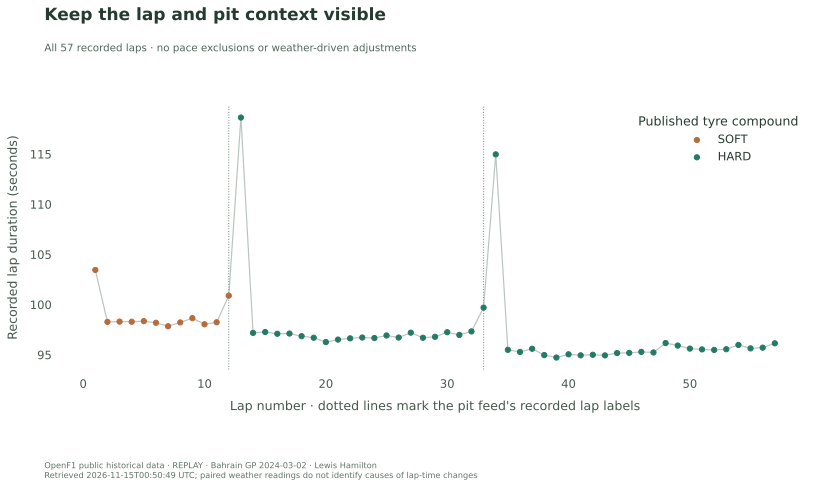

In [14]:
fig, ax = plt.subplots(figsize=(11.8, 7.2))
ax.plot(timing.lap_number, timing.lap_duration, color="#BAC5BD", linewidth=1.2)
for compound, color in [("SOFT", "#B66B3D"), ("HARD", "#237B65")]:
    selected = timing.loc[timing.compound.eq(compound)]
    ax.scatter(selected.lap_number, selected.lap_duration, color=color, s=28, label=compound, zorder=3)
for lap in driver_pits.lap_number:
    ax.axvline(lap, color="#72877A", linewidth=1, linestyle=":")
ax.set_xlabel("Lap number · dotted lines mark the pit feed's recorded lap labels")
ax.set_ylabel("Recorded lap duration (seconds)")
ax.legend(title="Published tyre compound", loc="upper right")
finish(
    fig,
    "Keep the lap and pit context visible",
    "All 57 recorded laps · no pace exclusions or weather-driven adjustments",
    chart_source,
    name="session-lap-context",
)

### Match backwards in time, then enforce an age limit

The ASOF join chooses the most recent weather record **at or before** each lap's start, within the same session. A future reading is never borrowed. Measure elapsed seconds, retain the raw paired record and expose a separate accepted-temperature column only when its age is within the stated limit. A rejected reading does not remove the lap.

These are circuit weather observations, not temperature measurements at the car. The tolerance expresses an analytical freshness choice. Narrowing it changes coverage; it does not improve the underlying readings or make weather a cause of lap-time changes.

In [15]:
%%sql weather_summary <<
SELECT count(*) AS laps,count(weather_time) AS paired_laps,
       count(*) FILTER(WHERE weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }}) AS accepted_laps,
       count(DISTINCT weather_time) FILTER(WHERE weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }}) AS accepted_observations,
       min(track_temperature) FILTER(WHERE weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }}) AS accepted_min_track_c,
       max(track_temperature) FILTER(WHERE weather_age_seconds <= {{ MAX_WEATHER_AGE_SECONDS }}) AS accepted_max_track_c,
       max(weather_age_seconds) AS oldest_pair_seconds
FROM lap_context;

In [16]:
display(weather_summary)
display(
    timing[
        [
            "lap_number",
            "date_start",
            "weather_time",
            "weather_age_seconds",
            "weather_accepted",
            "accepted_track_temperature",
        ]
    ].head(8)
)
w = weather_summary.iloc[0]
prose(
    f"A **{MAX_WEATHER_AGE_SECONDS}-second** limit accepts weather for **{int(w.accepted_laps)} of {int(w.laps)} laps**, using **{int(w.accepted_observations)} distinct observations**. The oldest preceding pair is **{float(w.oldest_pair_seconds):.1f} seconds** old. Accepted circuit temperatures span **{w.accepted_min_track_c}–{w.accepted_max_track_c} °C**; NULL means no eligible reading, not zero temperature. All laps and original pairs remain available for audit."
)

,laps,paired_laps,accepted_laps,accepted_observations,accepted_min_track_c,accepted_max_track_c,oldest_pair_seconds
0,57,57,57,57,21.9,23.8,59.967


,lap_number,date_start,weather_time,weather_age_seconds,weather_accepted,accepted_track_temperature
0,1,2024-03-02 15:03:42.341000+00:00,2024-03-02 15:02:56.565000+00:00,45.776,True,23.8
1,2,2024-03-02 15:05:25.792000+00:00,2024-03-02 15:04:56.561000+00:00,29.231,True,23.8
2,3,2024-03-02 15:07:04.200000+00:00,2024-03-02 15:06:56.557000+00:00,7.643,True,23.8
3,4,2024-03-02 15:08:42.487000+00:00,2024-03-02 15:07:56.551000+00:00,45.936,True,23.8
4,5,2024-03-02 15:10:20.703000+00:00,2024-03-02 15:09:56.553000+00:00,24.150,True,23.6
5,6,2024-03-02 15:11:59.143000+00:00,2024-03-02 15:11:56.552000+00:00,2.591,True,23.5
6,7,2024-03-02 15:13:37.347000+00:00,2024-03-02 15:12:56.556000+00:00,40.791,True,23.5
7,8,2024-03-02 15:15:15.137000+00:00,2024-03-02 15:14:56.565000+00:00,18.572,True,23.7


A **60-second** limit accepts weather for **57 of 57 laps**, using **57 distinct observations**. The oldest preceding pair is **60.0 seconds** old. Accepted circuit temperatures span **21.9–23.8 °C**; NULL means no eligible reading, not zero temperature. All laps and original pairs remain available for audit.

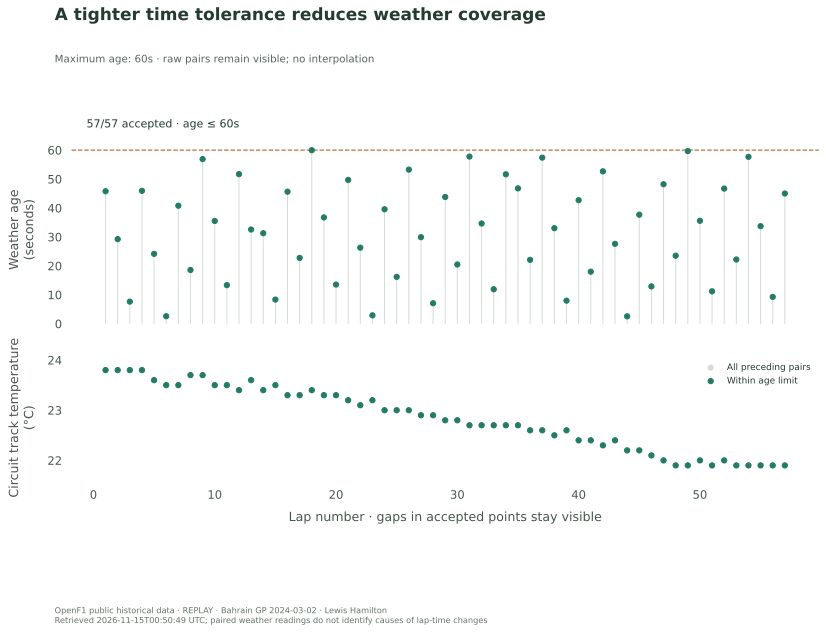

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11.8, 9.4), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
accepted = timing.weather_accepted
colors = np.where(accepted, "#237B65", "#B66B3D")
axes[0].vlines(timing.lap_number, 0, timing.weather_age_seconds, color="#D3DCD5", linewidth=1)
axes[0].scatter(timing.lap_number, timing.weather_age_seconds, c=colors, s=28, zorder=3)
axes[0].axhline(MAX_WEATHER_AGE_SECONDS, color="#B66B3D", linestyle="--", linewidth=1.2)
axes[0].set_ylim(0, max(65, float(timing.weather_age_seconds.max()) + 5, MAX_WEATHER_AGE_SECONDS + 5))
axes[0].set_ylabel("Weather age\n(seconds)")
axes[0].text(
    0.02,
    1.03,
    f"{int(accepted.sum())}/{len(timing)} accepted · age ≤ {MAX_WEATHER_AGE_SECONDS}s",
    transform=axes[0].transAxes,
    va="bottom",
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
)
axes[1].scatter(
    timing.lap_number, timing.track_temperature, color="#D3DCD5", s=26, label="All preceding pairs"
)
axes[1].scatter(
    timing.loc[accepted, "lap_number"],
    timing.loc[accepted, "accepted_track_temperature"],
    color="#237B65",
    s=28,
    label="Within age limit",
)
axes[1].set_ylim(float(timing.track_temperature.min()) - 0.3, float(timing.track_temperature.max()) + 0.3)
axes[1].set_ylabel("Circuit track temperature\n(°C)")
axes[1].set_xlabel("Lap number · gaps in accepted points stay visible")
axes[1].legend(loc="upper right", fontsize=9)
finish(
    fig,
    "A tighter time tolerance reduces weather coverage",
    f"Maximum age: {MAX_WEATHER_AGE_SECONDS}s · raw pairs remain visible; no interpolation",
    chart_source,
    name=f"session-weather-{MAX_WEATHER_AGE_SECONDS}",
)

In [18]:
%%sql checks <<
SELECT 'One meeting/session/driver identity' AS check_name,
 (SELECT count(*)=1 FROM sessions s JOIN meetings m USING(meeting_key) JOIN drivers d USING(session_key) JOIN results r USING(session_key,driver_number) WHERE s.session_key=9472 AND d.driver_number=44) AS passed
UNION ALL SELECT 'Unique driver and result keys',(SELECT count(*)=count(DISTINCT driver_number) FROM drivers) AND (SELECT count(*)=count(DISTINCT driver_number) FROM results)
UNION ALL SELECT 'Unique ordered source laps',(SELECT count(*)=count(DISTINCT lap_number) AND min(lap_number)=1 AND max(lap_number)=count(*) FROM laps)
UNION ALL SELECT 'Stint and weather joins preserve every lap',(SELECT count(*) FROM laps)=(SELECT count(*) FROM lap_context) AND (SELECT count(*)=count(DISTINCT lap_number) FROM lap_context)
UNION ALL SELECT 'Every lap has a stint',NOT EXISTS(SELECT 1 FROM lap_context WHERE stint_number IS NULL)
UNION ALL SELECT 'Weather timestamps unique within session',(SELECT count(*)=count(DISTINCT date) FROM weather)
UNION ALL SELECT 'Weather never comes from the future',NOT EXISTS(SELECT 1 FROM lap_context WHERE weather_age_seconds<0)
UNION ALL SELECT 'No more recent preceding weather skipped',NOT EXISTS(SELECT 1 FROM lap_context l JOIN weather w ON l.session_key=w.session_key AND w.date<=l.date_start AND w.date>l.weather_time)
UNION ALL SELECT 'Result and lap counts agree',(SELECT count(*) FROM laps)=(SELECT number_of_laps FROM results WHERE driver_number=44)
UNION ALL SELECT 'Stint lap intervals reconcile',(SELECT sum(lap_end-lap_start+1) FROM stints WHERE driver_number=44)=(SELECT count(*) FROM laps);

In [19]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert len(timing) == int(w.laps)
assert int(timing.weather_accepted.sum()) == int(w.accepted_laps)
assert timing.loc[~timing.weather_accepted, "accepted_track_temperature"].isna().all()
prose(
    "Ten SQL invariants and acceptance/null-preservation checks passed. The time tolerance changes only which already-paired temperatures are eligible."
)

,check_name,passed
0,One meeting/session/driver identity,True
1,Unique driver and result keys,True
2,Unique ordered source laps,True
3,Stint and weather joins preserve every lap,True
4,Every lap has a stint,True
5,Weather timestamps unique within session,True
6,Weather never comes from the future,True
7,No more recent preceding weather skipped,True
8,Result and lap counts agree,True
9,Stint lap intervals reconcile,True


Ten SQL invariants and acceptance/null-preservation checks passed. The time tolerance changes only which already-paired temperatures are eligible.

### Experiment: require weather within 15 seconds

Change only **MAX_WEATHER_AGE_SECONDS=60 → 15**. Predict which dots fall above the new boundary. The eight source tables, session identity, lap durations, stint intervals and pit events must remain unchanged; only weather acceptance and its derived temperature range change. Compare coverage before interpreting the smaller set.

Source: [OpenF1](https://openf1.org/), public historical responses. Source data rights remain with their providers. These examples are not affiliated with Formula 1 or the FIA.

In [20]:
session.close()
recording.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-f1](https://github.com/Query-farm/vgi-f1)